In [7]:
import os
os.chdir(r"D:\product-analytics-ecommerce")
import duckdb, pandas as pd
import matplotlib.pyplot as plt
con = duckdb.connect("data/processed/project.duckdb")

In [8]:
import os
print(os.getcwd())
print(os.listdir("sql"))

D:\product-analytics-ecommerce
['01_funnel.sql']


In [9]:
funnel_sql = open("sql/01_funnel.sql").read()
funnel = con.execute(funnel_sql).df()
funnel

,viewers,added_to_cart,buyers,view_to_cart_pct,cart_to_purchase_pct,overall_conversion_pct,all_purchasers
0,369664.0,82732.0,39979.0,22.38,48.32,10.81,44185.0


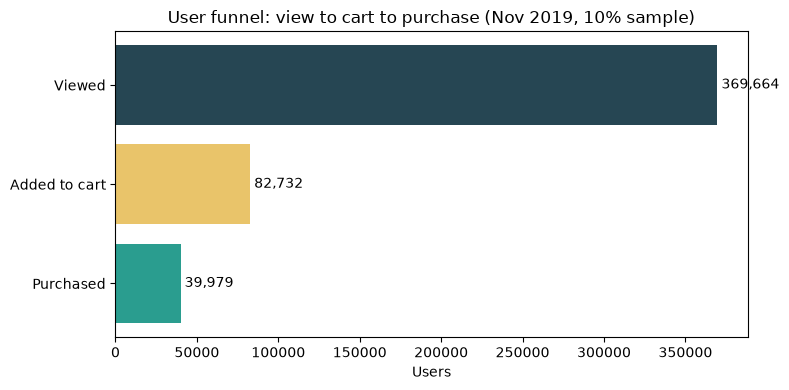

In [10]:
stages = ["Viewed", "Added to cart", "Purchased"]
values = [int(funnel.viewers[0]), int(funnel.added_to_cart[0]), int(funnel.buyers[0])]

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.barh(stages[::-1], values[::-1], color=["#2a9d8f", "#e9c46a", "#264653"])
for bar, v in zip(bars, values[::-1]):
    ax.text(v, bar.get_y() + bar.get_height()/2, f" {v:,}", va="center")
ax.set_title("User funnel: view to cart to purchase (Nov 2019, 10% sample)")
ax.set_xlabel("Users")
plt.tight_layout()
plt.savefig("images/funnel.png", dpi=150)
plt.show()

In [11]:
by_cat = con.execute("""
WITH user_cat AS (
  SELECT
    user_id,
    split_part(category_code, '.', 1) AS category,
    MAX(CASE WHEN event_type = 'view' THEN 1 ELSE 0 END) AS viewed,
    MAX(CASE WHEN event_type = 'cart' THEN 1 ELSE 0 END) AS carted,
    MAX(CASE WHEN event_type = 'purchase' THEN 1 ELSE 0 END) AS purchased
  FROM events_clean
  WHERE category_code IS NOT NULL
  GROUP BY user_id, split_part(category_code, '.', 1)
)
SELECT
  category,
  SUM(viewed) AS viewers,
  SUM(viewed * carted) AS carts,
  SUM(viewed * carted * purchased) AS buyers,
  ROUND(100.0 * SUM(viewed * carted) / SUM(viewed), 2) AS view_to_cart_pct,
  ROUND(100.0 * SUM(viewed * carted * purchased) / NULLIF(SUM(viewed * carted), 0), 2) AS cart_to_purchase_pct
FROM user_cat
GROUP BY category
HAVING SUM(viewed) >= 1000
ORDER BY viewers DESC
""").df()
by_cat

,category,viewers,carts,buyers,view_to_cart_pct,cart_to_purchase_pct
0,electronics,205840.0,45801.0,22762.0,22.25,49.70
1,appliances,70844.0,13116.0,5872.0,18.51,44.77
2,apparel,42402.0,2334.0,759.0,5.50,32.52
3,computers,36024.0,4624.0,1885.0,12.84,40.77
4,furniture,28115.0,1961.0,703.0,6.97,35.85
5,auto,16416.0,1731.0,702.0,10.54,40.55
6,kids,14465.0,929.0,359.0,6.42,38.64
7,construction,13864.0,1460.0,560.0,10.53,38.36
8,accessories,7069.0,379.0,138.0,5.36,36.41
9,sport,4723.0,260.0,95.0,5.50,36.54


In [12]:
con.close()